# Choosing the shifts a week ahead

**Contents**

- Objective
- 1\. Timing: what is known a week ahead
- 2\. Data and features
- 3\. The model
- 4\. Scores
- 5\. Rest between shifts
- 6\. Plan the week, adjust the day before
- 7\. A decision rule instead of a model
    - 7.1 The rule and its variants
    - 7.2 The rule against the week-ahead model
    - 7.3 Rest and start changes
    - 7.4 The rule's plan, adjusted the day before
- 8\. Every schedule on one denominator, with the 2026 reserve
- What a week's notice costs

## Objective

The main notebook, `de_price_forecast.ipynb`, picks each day's shift at 11:55 the day before. Here the plant fixes all seven shifts of the coming week at once, which is the notice a crew roster needs. The question is how much of the saving survives when the forecast has to reach up to a week ahead.

Everything else stays as in the main notebook: one 8-hour shift a day starting between 00:00 and 16:00, 500 MWh, the same night and weekend premium, the same `saving_share` and the same years. Only the inputs change, because fewer of them are known a week early.


## 1. Timing: what is known a week ahead

The schedule for Monday to Sunday is fixed on the Sunday before, at 11:55, the same time of day as the main notebook's gate. By then Sunday's own prices are public, since its auction cleared on Saturday at noon. So the last known prices are the Sunday's, and the forecast reaches 1 day ahead for Monday and 7 days ahead for Sunday.

That rules out three kinds of input:

| Input in the main model | A week ahead |
|---|---|
| Same hour on D-1 and D-2 (lag 24 and 48) | Not known for Tuesday to Sunday. Replaced by the same hour on the decision Sunday |
| D-1's mean, min and max, and the 7-day and 30-day means up to D-1 | Replaced by the same statistics up to the decision Sunday |
| The TSO's day-ahead load, solar and wind forecasts | Not published that far out. Energy-Charts, the source of all data here, serves load only as a day-ahead forecast, and a week-ahead load forecast would need ENTSO-E's API, a key and a new fetcher, so it is left out |

The calendar and the price at the same hour 7 days earlier stay legal for every day of the week: for the Sunday being scheduled, 7 days back is the decision Sunday itself. The week-ahead model therefore sees the clock and recent prices only, nothing about the weather.


Load the libraries and the fetch functions, and set the table display defaults.


In [1]:
import numpy as np
import polars as pl
from plotnine import (
    aes,
    facet_wrap,
    geom_hline,
    geom_line,
    geom_point,
    geom_text,
    ggplot,
    labs,
    scale_x_continuous,
    theme,
    theme_minimal,
    theme_set,
)
from xgboost import XGBRegressor

from lib.data_schemas import CombinedDataSchema
from lib.decision import (
    complete_shift_windows,
    flex_check,
    make_plan,
    pick_freely,
    pick_near_plan,
    pick_weekly,
    pick_with_rest,
    premium,
    rest_check,
    schedule_summary,
    week_mean_premium,
)
from lib.evaluation import (
    CVScores,
    Scores,
    block_bootstrap_means,
    cross_validate,
    evaluate,
    fold_sd_lead,
    summarise_folds,
)
from lib.fetching import fetch_de_prices, fetch_forecasts, fetch_neighbor_prices
from lib.modeling import df_to_np, trailing_hourly_mean
from lib.splitting import make_folds

# a kernel has no terminal, so polars would squeeze every table into ~100 characters
_ = (
    pl.Config.set_tbl_rows(30)
    .set_tbl_cols(-1)  # show every column
    .set_tbl_width_chars(1000)  # wide tables use the pane instead of wrapping
    .set_fmt_str_lengths(60)
    .set_float_precision(3)
)
theme_set(theme_minimal() + theme(figure_size=(10, 4.5), legend_position="top"))

## 2. Data and features

The hourly table is built exactly as in sections 1.2 and 4.1 of the main notebook: every file averaged to UTC hours, joined onto the prices, calendar columns in German time, validated against the same data model.


Load the three raw files, put them on one hourly grid, join them, and validate the result.


In [2]:
def to_hourly(raw: pl.DataFrame) -> pl.DataFrame:
    return (
        raw.sort("utc_timestamp")
        .group_by_dynamic("utc_timestamp", every="1h")
        .agg(pl.all().mean())
    )


local = pl.col("utc_timestamp").dt.convert_time_zone("Europe/Berlin")
merged = (
    to_hourly(fetch_de_prices())
    .join(to_hourly(fetch_forecasts()), on="utc_timestamp", how="left")
    .join(to_hourly(fetch_neighbor_prices()), on="utc_timestamp", how="left")
    .with_columns(
        date=local.dt.date(),
        year=local.dt.year(),
        hour=local.dt.hour(),
        weekday=local.dt.weekday(),
        fc_residual=pl.col("fc_load")
        - pl.sum_horizontal("fc_solar", "fc_wind_onshore", "fc_wind_offshore"),
    )
)
df = CombinedDataSchema.validate(merged).sort("utc_timestamp")
df.height

68183

Validation passed, so the table is the main notebook's, hour for hour.


Two feature sets are built from it. The day-ahead set is the final model's 17 columns from the main notebook, rebuilt here so both models are scored side by side. The week-ahead set swaps every price input for its week-ahead version and has no forecasts:

- `decision_date`: the Sunday the week's schedule is fixed on, `date - weekday` days, since Monday is weekday 1 and Sunday weekday 7.
- `price_decision_day`: the price at the same hour on `decision_date`. For Monday it is the same as lag 24, for Sunday the same as lag 168.
- `price_lag7d`, `price_lag14d`: the same hour 7 and 14 days earlier.

The week-ahead prices are looked up by German date and hour rather than by shifting a fixed number of hours, as the main notebook's lags do. A shift of 168 hours reads one hour too far forward on the Sunday after the October clock change, where 23:00 lands on Monday 00:00, a price not yet public on the decision Sunday.
- `decision_day_mean`, `decision_day_min`, `decision_day_max`, `decision_mean_7d`, `decision_mean_30d`: the decision Sunday's mean, min and max price, and the mean daily price over the 7 and 30 days up to and including it.

These mirror the main model's eight price-memory columns one for one, which keeps the two models as alike as the timing allows. `price_lag24` is kept in the table for one job only: MASE is measured against same hour yesterday in both notebooks.


Compute each day's price statistics, then attach them to the next day for the day-ahead set and to the coming week for the week-ahead set.


In [3]:
daily = (
    df.group_by("date")
    .agg(
        day_mean=pl.col("price_da").mean(),
        day_min=pl.col("price_da").min(),
        day_max=pl.col("price_da").max(),
    )
    .sort("date")
    .with_columns(
        mean_7d=pl.col("day_mean").rolling_mean(7),
        mean_30d=pl.col("day_mean").rolling_mean(30),
    )
)
# the day-ahead set sees the statistics up to D-1, as in the main notebook
day_ahead_stats = daily.select(
    (pl.col("date") + pl.duration(days=1)).alias("date"),
    prev_day_mean="day_mean",
    prev_day_min="day_min",
    prev_day_max="day_max",
    mean_7d="mean_7d",
    mean_30d="mean_30d",
)
# the week-ahead set sees them up to the decision Sunday
week_ahead_stats = daily.select(
    pl.col("date").alias("decision_date"),
    decision_day_mean="day_mean",
    decision_day_min="day_min",
    decision_day_max="day_max",
    decision_mean_7d="mean_7d",
    decision_mean_30d="mean_30d",
)
# one price per German date and hour, for the week-ahead lookups below; the 25-hour day
# in October has hour 2 twice, and the two are averaged
local_prices = df.group_by("date", "hour").agg(price=pl.col("price_da").mean())

features = (
    df.with_columns(
        # the grid is hourly with no gaps, so shifting by rows is shifting by hours
        price_lag24=pl.col("price_da").shift(24),
        price_lag48=pl.col("price_da").shift(48),
        price_lag168=pl.col("price_da").shift(168),
        month=pl.col("date").dt.month(),
        is_weekend=pl.col("weekday") >= 6,
        decision_date=pl.col("date") - pl.duration(days=pl.col("weekday")),
    )
    .with_columns(
        # the day each week-ahead price is read from
        price_decision_day_source=pl.col("decision_date"),
        price_lag7d_source=pl.col("date") - pl.duration(days=7),
        price_lag14d_source=pl.col("date") - pl.duration(days=14),
    )
    .join(day_ahead_stats, on="date", how="left")
    .join(week_ahead_stats, on="decision_date", how="left")
)
for price in ("price_decision_day", "price_lag7d", "price_lag14d"):
    features = features.join(
        local_prices.rename({"date": f"{price}_source", "price": price}),
        on=[f"{price}_source", "hour"],
        how="left",
    )
features = features.sort("utc_timestamp").with_columns(
    # the March clock change skips hour 2, so a lookup into that day finds no price for
    # hour 2 and takes the hour before it, which is earlier and so still known
    pl.col("price_decision_day", "price_lag7d", "price_lag14d").forward_fill()
)

Write out both column lists.


In [4]:
CALENDAR = ["hour", "weekday", "month", "is_weekend"]
DAY_AHEAD_COLUMNS = [
    *CALENDAR,
    "fc_load",
    "fc_solar",
    "fc_wind_onshore",
    "fc_wind_offshore",
    "fc_residual",
    "price_lag24",
    "price_lag48",
    "price_lag168",
    "prev_day_mean",
    "prev_day_min",
    "prev_day_max",
    "mean_7d",
    "mean_30d",
]
WEEK_AHEAD_COLUMNS = [
    *CALENDAR,
    "price_decision_day",
    "price_lag7d",
    "price_lag14d",
    "decision_day_mean",
    "decision_day_min",
    "decision_day_max",
    "decision_mean_7d",
    "decision_mean_30d",
]

Check that every week-ahead price column is known at the decision time. `latest_day_used` is the last delivery day a column reads, counted from the decision Sunday: 0 means the Sunday itself, a positive number would mean a price that is not yet public. The check runs over every hour of every week in the data.


In [5]:
pl.DataFrame(
    [
        {
            "column": column,
            "latest_day_used": features.select(
                (pl.col(source) - pl.col("decision_date")).dt.total_days().max()
            ).item(),
        }
        for column, source in [
            ("price_decision_day", "price_decision_day_source"),
            ("price_lag7d", "price_lag7d_source"),
            ("price_lag14d", "price_lag14d_source"),
            ("decision_day_mean, min, max, mean_7d, mean_30d", "decision_date"),
        ]
    ]
)

column,latest_day_used
str,i64
"""price_decision_day""",0
"""price_lag7d""",0
"""price_lag14d""",-7
"""decision_day_mean, min, max, mean_7d, mean_30d""",0


No column reads past the decision Sunday, so the whole week-ahead set is known when the week's shifts are fixed.


Split the table into the development years and the 2025 test year. Each model drops only the first days of 2019 that its own columns cannot fill, so the day-ahead rows are exactly the main notebook's `dev`. The 2026 reserve is used only in section 8.


In [6]:
TEST_YEAR = 2025
FOLDS = {"fold-1": 2023, "fold-2": 2024}  # fold name: validation year

before_test = features.filter(pl.col("year") < TEST_YEAR)
dev_day_ahead = before_test.drop_nulls(DAY_AHEAD_COLUMNS)
dev_week_ahead = before_test.drop_nulls(WEEK_AHEAD_COLUMNS)
test_2025 = features.filter(pl.col("year") == TEST_YEAR)

parts: list[tuple[str, pl.DataFrame, list[str]]] = [
    ("dev-day-ahead", dev_day_ahead, DAY_AHEAD_COLUMNS),
    ("dev-week-ahead", dev_week_ahead, WEEK_AHEAD_COLUMNS),
    (
        "test-2025",
        test_2025,
        list(dict.fromkeys(DAY_AHEAD_COLUMNS + WEEK_AHEAD_COLUMNS)),
    ),
]
pl.DataFrame(
    [
        {
            "set": name,
            "hours": part.height,
            "first_day": part["date"].min(),
            "last_day": part["date"].max(),
            "missing_feature_values": part.select(columns)
            .null_count()
            .sum_horizontal()
            .item(),
        }
        for name, part, columns in parts
    ]
)

set,hours,first_day,last_day,missing_feature_values
str,i64,date,date,i64
"""dev-day-ahead""",51888,2019-01-31,2024-12-31,0
"""dev-week-ahead""",51792,2019-02-04,2024-12-31,0
"""test-2025""",8760,2025-01-01,2025-12-31,0


The week-ahead training data starts a week later, on 2019-02-07, because its 30-day mean has to end on the Sunday before. Neither model has a missing value in 2025.


## 3. The model

Both rows use the main notebook's final model with its settings unchanged: XGBoost alone, 200 trees 3 levels deep, a learning rate of 0.05. Nothing is tuned for the week-ahead inputs. The question is what the shorter view costs, and a new search now, with 2025 already scored, would be choosing on the test year again.

The week-ahead model is scored on 2025 as well. It does not compete with the day-ahead model for anything: the final model in the main notebook stays final whatever this one scores, so the 2025 number cannot feed back into a choice.


Build both models with the final settings.


In [7]:
FINAL_SETTINGS = {"max_depth": 3, "learning_rate": 0.05, "n_estimators": 200}
models = {
    "day-ahead": (
        XGBRegressor(random_state=0, **FINAL_SETTINGS),
        DAY_AHEAD_COLUMNS,
        dev_day_ahead,
    ),
    "week-ahead": (
        XGBRegressor(random_state=0, **FINAL_SETTINGS),
        WEEK_AHEAD_COLUMNS,
        dev_week_ahead,
    ),
}

## 4. Scores

The metrics are the main notebook's, from `evaluate` in `lib/evaluation.py`:

- `saving_share`: `(standard - shift_cost) / (standard - hindsight)`, each a year's average cost in EUR/MWh, electricity plus premium. 100% matches hindsight, 0% is the standard 06:00 to 14:00 shift.
- `saving_eur_per_year`: what the picked shifts save against the standard shift over a year, for 500 MWh a day.
- `mae` in EUR/MWh, and `mase`, the MAE over that of same hour yesterday, for the course.

Two references bound the result. `last-year-profile` picks every day's shift from the previous year's average price by hour, so it could be fixed a year ahead: it is the floor for any schedule set in advance. `standard-shift` scores 0 by definition. `cross_validate` fits each model on the years before each validation year, as in the main notebook, and the validation columns are the mean of 2023 and 2024.


Score both models on the validation years, then refit each on all development years and score 2025.


In [8]:
validation: dict[str, CVScores] = {}
validation_years: dict[str, list[Scores]] = {}  # 2023, then 2024
test_scores: dict[str, Scores] = {}
validation_forecasts: dict[str, pl.DataFrame] = {}  # out-of-fold, 2023 and 2024
test_forecasts: dict[str, np.ndarray] = {}
for name, (model, columns, dev) in models.items():
    validation[name], validation_forecasts[name] = cross_validate(
        model, columns, dev, FOLDS
    )
    validation_years[name] = [
        evaluate(year_frame, year_frame["pred"].to_numpy())
        for year_frame in (
            validation_forecasts[name].filter(pl.col("year") == year)
            for year in FOLDS.values()
        )
    ]
    _ = model.fit(df_to_np(dev, columns), dev["price_da"].to_numpy())
    test_forecasts[name] = model.predict(df_to_np(test_2025, columns))
    test_scores[name] = evaluate(test_2025, test_forecasts[name])

Score the two references the same way: on each validation year, then on 2025, each year's profile taken from the year before it.


In [9]:
def reference_scores(fit: pl.DataFrame, valid: pl.DataFrame) -> dict[str, Scores]:
    last_year = (
        fit.filter(pl.col("year") == fit["year"].max())
        .group_by("hour")
        .agg(profile=pl.col("price_da").mean())
    )
    profile = valid.join(last_year, on="hour", how="left").sort("utc_timestamp")[
        "profile"
    ]
    standard = np.where(valid["hour"].is_between(6, 13).to_numpy(), 0.0, 1.0)
    return {
        "last-year-profile": evaluate(valid, profile.to_numpy(), report_error=False),
        "standard-shift": evaluate(
            valid, standard, pick_with_premium=False, report_error=False
        ),
    }


per_fold = [
    reference_scores(fit, valid)
    for fit, valid in make_folds(dev_day_ahead, FOLDS).values()
]
for name in ("last-year-profile", "standard-shift"):
    validation_years[name] = [fold[name] for fold in per_fold]
    validation[name] = summarise_folds(validation_years[name])
test_scores |= reference_scores(dev_day_ahead, test_2025)

Line the four up: validation mean first, then 2025.


In [10]:
pl.DataFrame(
    [
        {
            "method": name,
            "saving_share_validation": validation[name]["saving_share"],
            "saving_share_2025": test_scores[name]["saving_share"],
            "saving_eur_per_year_validation": validation[name]["saving_eur_per_year"],
            "saving_eur_per_year_2025": test_scores[name]["saving_eur_per_year"],
            "mae_validation": validation[name]["mae"],
            "mae_2025": test_scores[name]["mae"],
            "mase_2025": test_scores[name]["mase"],
        }
        for name in ("day-ahead", "week-ahead", "last-year-profile", "standard-shift")
    ]
)

method,saving_share_validation,saving_share_2025,saving_eur_per_year_validation,saving_eur_per_year_2025,mae_validation,mae_2025,mase_2025
str,f64,f64,f64,f64,f64,f64,f64
"""day-ahead""",0.956,0.964,3895302.402,4309336.406,16.961,16.404,0.632
"""week-ahead""",0.861,0.872,3508723.089,3899264.219,29.543,26.369,1.016
"""last-year-profile""",0.553,0.683,2252419.630,3054707.188,null,null,null
"""standard-shift""",0.000,0.000,0.000,0.000,null,null,null


A week ahead, the model gets 86.1% of the possible saving on the validation years and 87.2% on 2025, against 95.6% and 96.4% for the day-ahead model. On 2025 that is 3.90 million EUR a year instead of 4.31 million: fixing the week early costs about 410,000 EUR a year, and it still saves about 850,000 more than last year's profile.

Its price forecast is worse than same hour yesterday (MASE 1.02), yet it picks the shift well. The level is hard to see a week out, but the shift only depends on the shape of the day, and the clock and last week's prices carry most of that. Year by year it gets 83.6% in 2023, 88.7% in 2024 and 87.2% in 2025: worst in 2023, the first year after the gas crisis, when the level moved most.


## 5. Rest between shifts

German law (Arbeitszeitgesetz §5) requires 11 hours off between two shifts, so a shift may start at most 5 hours earlier than the day before's. Section 8.4 of the main notebook counts how often the day-ahead schedules break this and what keeping it costs; this section adds the week-ahead schedule, with the same columns:

- `rest_breaks`, `rest_break_share`: days in 2025 whose shift starts less than 11 hours after the day before's ends, as a count and as a share of the year's days. `rest_breaks_validation`, `rest_break_share_validation`: the same over 2023 and 2024 together, from the out-of-fold forecasts.
- `saving_share`: from the free choice, as in section 4.
- `saving_share_rest`: the same share with the rule kept. Each day takes its cheapest forecast shift among those that start at least 11 hours after the previous day's shift ends. A week-ahead plan is made in one go on the Sunday, but Sunday's own shift was fixed the week before, so day by day in date order gives the same constraint. Hindsight under the rule is the cheapest sequence over the whole year that never breaks it, found by dynamic programming.
- `saving_eur_per_year`: the free choice's saving against the standard 06:00 shift. `rest_eur_per_year`: how that saving changes when the rule is kept, negative when the rule costs money.

The rule compares clock hours, so on the two clock-change days a year the real rest is one hour shorter (March) or longer (October) than counted.


Count the rest breaks of each schedule on 2025 and on the validation years, and score each one with the rule kept.


In [11]:
test_rest_frame = test_2025.with_columns(
    day_ahead=pl.Series(test_forecasts["day-ahead"]),
    week_ahead=pl.Series(test_forecasts["week-ahead"]),
)
REST_SCORES = {
    "day-ahead": pl.col("day_ahead") + premium(),
    "week-ahead": pl.col("week_ahead") + premium(),
    "residual-load-rule": pl.col("fc_residual"),
}
rest_2025 = test_rest_frame.pipe(rest_check, REST_SCORES)

# the two models' validation rows differ in their first days of 2019, never in 2023 or
# 2024, so the forecasts line up on the timestamp
validation_rest_frame = (
    validation_forecasts["day-ahead"]
    .rename({"pred": "day_ahead"})
    .join(
        validation_forecasts["week-ahead"].select("utc_timestamp", week_ahead="pred"),
        on="utc_timestamp",
    )
)
# each validation year on its own, so no schedule runs across the gap between folds
rest_validation = (
    pl.concat(
        [
            validation_rest_frame.filter(pl.col("year") == year).pipe(
                rest_check, REST_SCORES
            )
            for year in FOLDS.values()
        ]
    )
    .group_by("schedule", maintain_order=True)
    .agg(
        rest_breaks_validation=pl.col("rest_breaks").sum(),
        rest_break_share_validation=pl.col("rest_breaks").sum() / pl.col("days").sum(),
    )
)
rest_2025.join(rest_validation, on="schedule").select(
    "schedule",
    "rest_breaks",
    "rest_break_share",
    "rest_breaks_validation",
    "rest_break_share_validation",
    "saving_share",
    "saving_share_rest",
    "saving_eur_per_year",
    "rest_eur_per_year",
)

schedule,rest_breaks,rest_break_share,rest_breaks_validation,rest_break_share_validation,saving_share,saving_share_rest,saving_eur_per_year,rest_eur_per_year
str,i64,f64,i64,f64,f64,f64,f64,f64
"""day-ahead""",20,0.055,74,0.101,0.964,0.931,4309336.406,-240215.000
"""week-ahead""",15,0.041,40,0.055,0.872,0.877,3899264.219,-65941.875
"""residual-load-rule""",43,0.118,106,0.145,0.941,0.858,4204679.688,-452832.031
"""hindsight""",26,0.071,72,0.098,1.000,1.000,4469477.031,-96875.000


The week-ahead schedule breaks the rest rule on 15 days of 2025 (4.1%) and on 40 validation days (5.5%), against 20 and 74 for the day-ahead model. Keeping the rule costs it 66,000 EUR a year, against 240,000 for the day-ahead model. With rest kept on both, choosing each day the day before saves about 236,000 EUR a year more than fixing the week on Sunday, instead of about 410,000.


## 6. Plan the week, adjust the day before

Crews need their shifts planned well ahead, and the day-ahead forecast picks the better shift. This section combines the two. Each day's shift is planned on the Sunday before, as in section 4, and at 11:55 the day before, the day-ahead model may move that day's start a few hours from the plan. The crew then knows its shift a week ahead, and it moves by a few hours at most. The plan rests on the weaker week-ahead forecast, which has no weather input: no TSO publishes wind or solar forecasts a week ahead, and the week-ahead load forecast is not in this data (section 1), but it is still a forecast of the coming week's prices, not a fixed timetable.

- Planned start: the week-ahead model's cheapest forecast shift, the schedule of section 4.
- Final start: the day-ahead model's cheapest forecast shift among the starts from `earlier` hours before to `later` hours after the planned one, still between 00:00 and 16:00. `pick_near_plan` in `lib/decision.py` makes this choice and `flex_check` scores it.
- Reach: either way, `either-way-1h` to `either-way-4h`, where the start may move up to W hours earlier or later; or earlier only, `earlier-only-1h` to `earlier-only-4h`, where the plan is the latest a shift can start. `either-way-0h` keeps the plan, so it is the week-ahead schedule. `any-start` allows 16 hours, which covers every start, so it is the day-ahead choice of the main notebook.
- With the rest rule kept, the plan is the week-ahead schedule with rest kept from section 5, and the final start must also come at least 11 hours after the previous day's final shift ends. A start that works always exists: the plan keeps the rule, so the planned start plus the later reach is never too early.
- `saving_share`: `(standard - shift_cost) / (standard - hindsight)` from the year's total costs. With the rule kept, hindsight is the cheapest rest-keeping sequence, as in section 5. `saving_eur_per_year`: the saving against the standard 06:00 shift over a year.
- `moved_share`: the share of 2025's days whose final start differs from the planned one. `mean_move_hours`: the mean distance moved, in hours, over all days.

The validation columns are the mean of 2023 and 2024, each year scored on its own.


Score every reach on 2025 and on each validation year, with the free choice and with the rest rule kept.


In [12]:
REACH_HOURS = [0, 1, 2, 3, 4]
# name: (hours the start may move earlier, hours it may move later)
REACHES: dict[str, tuple[int, int]] = {
    f"either-way-{hours}h": (hours, hours) for hours in REACH_HOURS
} | {f"earlier-only-{hours}h": (hours, 0) for hours in REACH_HOURS if hours > 0}
# every start from 00:00 to 16:00 is within 16 hours, so this is the day-ahead choice
REACHES["any-start"] = (16, 16)
plan_score = REST_SCORES["week-ahead"]
final_score = REST_SCORES["day-ahead"]

flex_2025 = test_rest_frame.pipe(flex_check, plan_score, final_score, REACHES)
# each validation year on its own, then the mean of the two, as in section 4
flex_validation = (
    pl.concat(
        [
            validation_rest_frame.filter(pl.col("year") == year).pipe(
                flex_check, plan_score, final_score, REACHES
            )
            for year in FOLDS.values()
        ]
    )
    .group_by("reach", "keep_rest", maintain_order=True)
    .agg(
        saving_share_validation=pl.col("saving_share").mean(),
        saving_eur_per_year_validation=pl.col("saving_eur_per_year").mean(),
    )
)
flex = flex_2025.join(flex_validation, on=["reach", "keep_rest"]).select(
    "reach",
    "keep_rest",
    "saving_share_validation",
    "saving_share",
    "saving_eur_per_year_validation",
    "saving_eur_per_year",
    "moved_share",
    "mean_move_hours",
)
flex

reach,keep_rest,saving_share_validation,saving_share,saving_eur_per_year_validation,saving_eur_per_year,moved_share,mean_move_hours
str,bool,f64,f64,f64,f64,f64,f64
"""either-way-0h""",false,0.861,0.872,3508723.089,3899264.219,0.000,0.000
"""either-way-1h""",false,0.882,0.893,3590501.151,3992941.094,0.345,0.345
"""either-way-2h""",false,0.882,0.896,3592445.738,4006027.031,0.348,0.384
"""either-way-3h""",false,0.884,0.898,3598322.505,4011435.469,0.356,0.430
"""either-way-4h""",false,0.885,0.902,3603459.699,4032627.969,0.370,0.521
"""earlier-only-1h""",false,0.868,0.881,3534314.006,3937238.125,0.137,0.137
"""earlier-only-2h""",false,0.869,0.883,3538873.344,3948357.344,0.137,0.164
"""earlier-only-3h""",false,0.870,0.884,3541118.113,3952452.969,0.140,0.189
"""earlier-only-4h""",false,0.869,0.888,3538992.331,3968613.750,0.145,0.236


Choosing freely, a reach of one hour either way lifts the 2025 saving share from 87.2% to 89.3%, or 3.99 million EUR a year: about 94,000 of the 410,000 EUR a year that a week's notice costs. Wider reaches add little, 90.2% at four hours, and the start moves on 35% to 37% of days, by 0.35 to 0.52 hours on average. On the validation years the gain is similar, from 86.1% to 88.2% at one hour and 88.5% at four, about 82,000 and 95,000 of a 387,000 gap. Moving earlier only wins back less than half as much as moving either way.

With the rest rule kept, the move recovers more. On the validation years every either-way reach of one hour or more saves more than choosing each day the day before, 3.60 million EUR a year at one hour and 3.61 million at four against 3.15 million. The likely reason is the one in section 8.4 of the main notebook: choosing one day at a time under the rule, a late shift today can rule out a cheap early shift tomorrow, and a plan that already keeps the rule holds each day's choice near a sequence that works. On 2025 the effect is smaller and the order flips: 3.92 million at one hour and 3.94 million at four, against 4.07 million for choosing each day the day before.


Plot the 2025 saving share against the reach, one panel for each setting, with the pure week-ahead and day-ahead levels as reference lines.


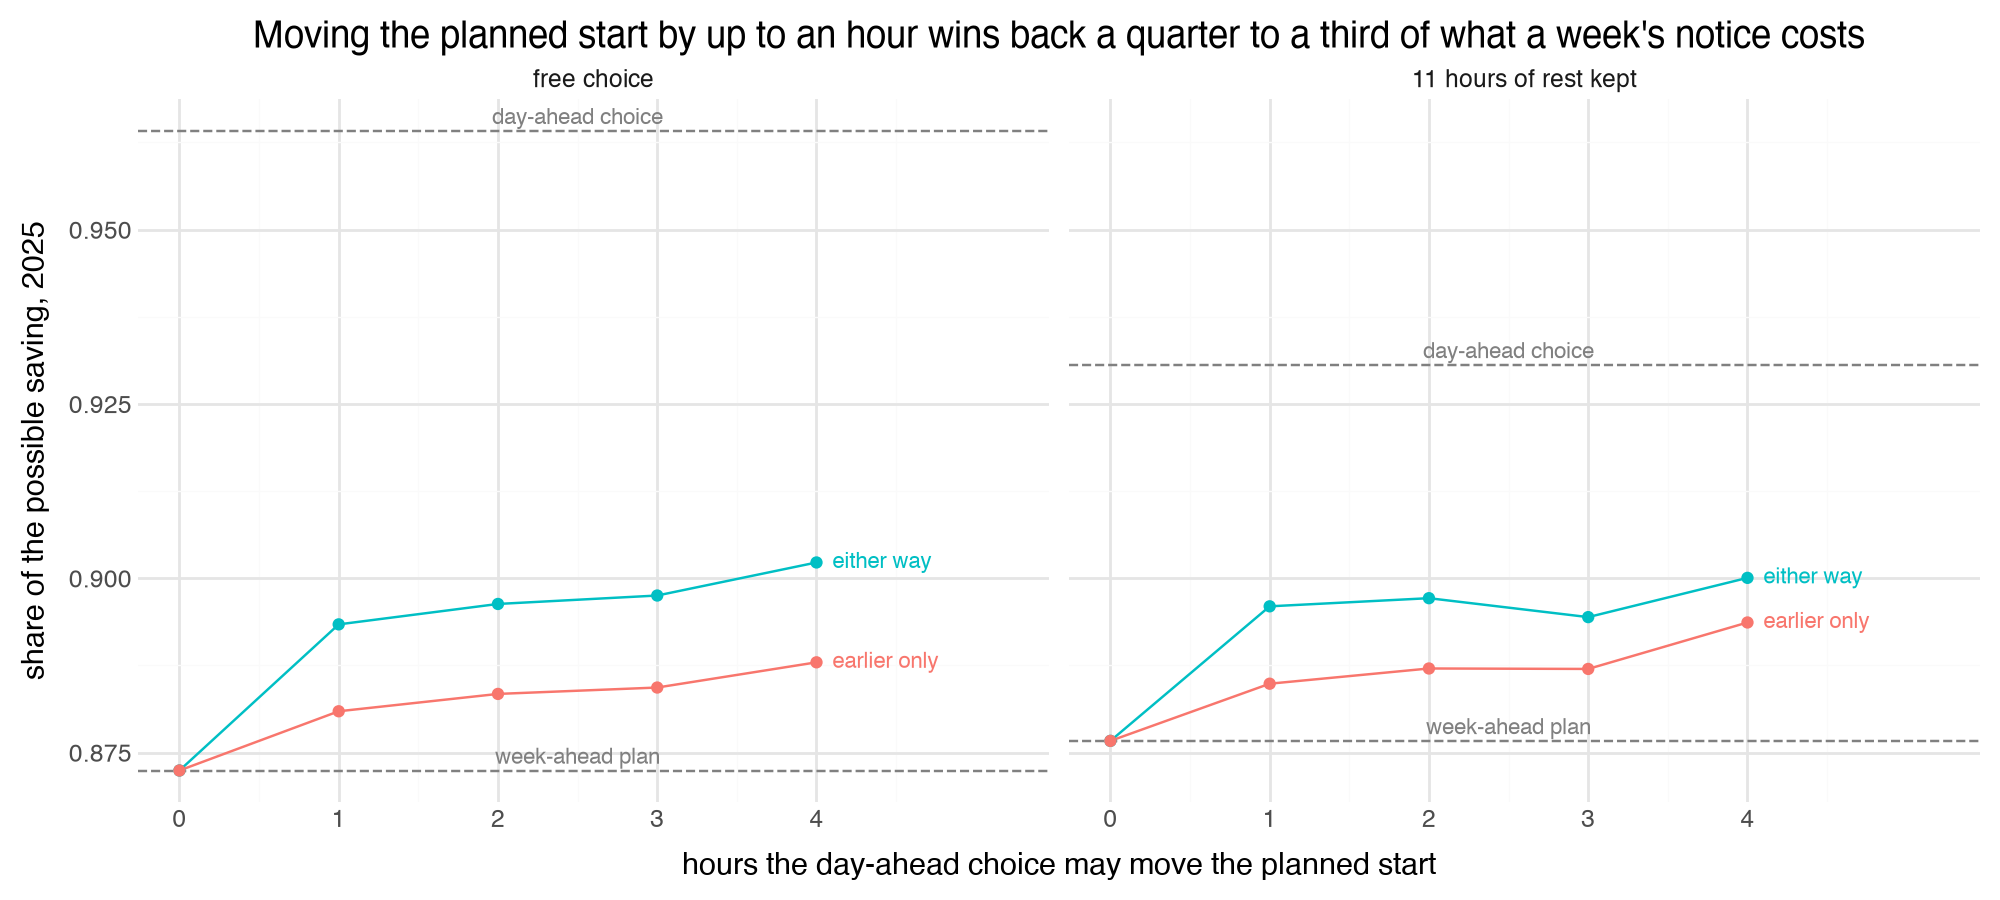

In [13]:
SETTING_NAMES = {False: "free choice", True: "11 hours of rest kept"}
# an ordered type, so the free choice is the first panel
SETTING_ORDER = pl.Enum(list(SETTING_NAMES.values()))
within_four = (pl.col("earlier") <= 4) & (pl.col("later") <= 4)
# the 0-hour reach starts both lines
either_way = flex_2025.filter(
    within_four, pl.col("earlier") == pl.col("later")
).with_columns(move=pl.lit("either way"), hours=pl.col("earlier"))
earlier_only = flex_2025.filter(within_four, pl.col("later") == 0).with_columns(
    move=pl.lit("earlier only"), hours=pl.col("earlier")
)
lines = pl.concat([either_way, earlier_only]).with_columns(
    setting=pl.col("keep_rest").replace_strict(
        SETTING_NAMES, return_dtype=SETTING_ORDER
    )
)
line_names = lines.filter(pl.col("hours") == 4)
references = pl.concat(
    [
        flex_2025.filter(pl.col("reach") == "any-start").with_columns(
            level=pl.lit("day-ahead choice")
        ),
        flex_2025.filter(pl.col("reach") == "either-way-0h").with_columns(
            level=pl.lit("week-ahead plan")
        ),
    ]
).with_columns(
    setting=pl.col("keep_rest").replace_strict(
        SETTING_NAMES, return_dtype=SETTING_ORDER
    )
)

(
    ggplot(lines, aes("hours", "saving_share"))
    + geom_hline(
        data=references,
        mapping=aes(yintercept="saving_share"),
        linetype="dashed",
        color="grey",
    )
    + geom_text(
        data=references,
        mapping=aes(x=2.5, y="saving_share", label="level"),
        va="bottom",
        size=8,
        color="grey",
    )
    + geom_line(aes(color="move"))
    + geom_point(aes(color="move"))
    + geom_text(
        data=line_names,
        mapping=aes(x=4.1, label="move", color="move"),
        ha="left",
        size=8,
    )
    + facet_wrap("setting")
    + scale_x_continuous(breaks=REACH_HOURS, limits=(0, 5.2))
    + labs(
        x="hours the day-ahead choice may move the planned start",
        y="share of the possible saving, 2025",
        title="Moving the planned start by up to an hour wins back a quarter to a third of what a week's notice costs",
    )
    + theme(legend_position="none")
)

## 7. A decision rule instead of a model

The week-ahead model sees the clock and last week's prices, nothing about the weather. A rule that only reads last week's prices sees almost the same, and needs no model. This section asks whether the model beats it.

The rule, `last-week`: on the decision Sunday, take each clock hour's mean settled price over the 7 days up to and including that Sunday, add the premium averaged over a week (`week_mean_premium`: the full 10 EUR/MWh from 22:00 to 06:00, two sevenths of it by day, the weekend's share), and run the cheapest 8-hour start from Monday to Sunday. Every day of the week gets the same score, so the week has one start.

Three new tools:

- `fold_sd_lead(first, second)`, in `lib/evaluation.py`: rule 1's test from the main notebook on one metric. It returns the gap in the mean over 2023 and 2024, first minus second, and the bar the gap must clear, the larger of the two options' fold SDs.

- `trailing_hourly_mean(prices, days, every)`, in `lib/modeling.py`: for each date and hour, the mean price at that hour over the `days` days ending on that date, `every` days apart. `every=7` averages the same weekday over several weeks. An hour missing from a day, such as 02:00 on the March clock change, drops out of the mean.
- `pick_weekly(windows, score, keep_rest)`, in `lib/decision.py`: one start for each Monday-to-Sunday week, the one whose score averaged over the week's days is lowest. With `keep_rest`, the new week's start may be at most 5 hours earlier than the last week's. `rest_check` and `flex_check` use it for schedules passed as weekly.

Nine ways to read last week's prices were scored on the validation years, and all nine are in the table. They differ in how far back they look and whether weekends get their own profile:

| Rule | Price profile for each hour | Starts |
|---|---|---|
| `last-week` | mean of the 7 days to the decision Sunday | one a week |
| `last-4-weeks` | mean of the 28 days to the decision Sunday | one a week |
| `last-week-by-day` | as `last-week`, but each day adds its own premium, so a weekend can start at another hour | one a day |
| `same-day-last-week` | the same day 7 days earlier | one a day |
| `same-weekday-4-weeks` | the same weekday in each of the last 4 weeks | one a day |
| `day-type-7-days` | weekdays: the last 5 weekdays; weekends: last Saturday and Sunday | one a day |
| `day-type-28-days` | the same over 28 days | one a day |
| `last-week-plus-day-type-offset` | `last-week` plus how much the day's type (weekday or weekend) differed from the 28-day mean at that hour | one a day |
| `last-week-plus-weekday-offset` | `last-week` plus how much the same weekday over 4 weeks differed from the 28-day mean at that hour | one a day |

The rule goes forward unless a variant beats it under rule 1 of the main notebook: a lead in mean saving share larger than the larger of the two fold SDs. Rules have no MAE, so a tie on saving share goes to the simpler rule, and `last-week` is the simplest: one profile and one start a week. Only `last-week` is scored on 2025, as a no-model reference beside the week-ahead model; no variant is.


### 7.1 The rule and its variants

Build every rule's price profile from the settled prices, each read by German date and hour.


In [14]:
weekdays_only = local_prices.filter(pl.col("date").dt.weekday() <= 5)
weekends_only = local_prices.filter(pl.col("date").dt.weekday() >= 6)


def profile_on(source: pl.DataFrame, name: str, on: str) -> pl.DataFrame:
    """A trailing mean as a lookup table: its `date` renamed to `on`, its mean to `name`."""
    return source.rename({"date": on, "mean_price": name})


profiles = {
    "mean_7d": local_prices.pipe(trailing_hourly_mean, 7),
    "mean_28d": local_prices.pipe(trailing_hourly_mean, 28),
    "weekday_7d": weekdays_only.pipe(trailing_hourly_mean, 7),
    "weekend_7d": weekends_only.pipe(trailing_hourly_mean, 7),
    "weekday_28d": weekdays_only.pipe(trailing_hourly_mean, 28),
    "weekend_28d": weekends_only.pipe(trailing_hourly_mean, 28),
}
rule_frame = features.select(
    "utc_timestamp", "date", "hour", "decision_date", "is_weekend", "price_lag7d"
).with_columns(week_before=pl.col("date") - pl.duration(days=7))
for name, profile in profiles.items():
    rule_frame = rule_frame.join(
        profile.pipe(profile_on, name, "decision_date"),
        on=["decision_date", "hour"],
        how="left",
    )
# the same weekday over the 4 weeks before the delivery day: the 4 weeks end on the
# day 7 days back, the last one known on the decision Sunday
rule_frame = rule_frame.join(
    local_prices.pipe(trailing_hourly_mean, 4, every=7).pipe(
        profile_on, "same_weekday_4w", "week_before"
    ),
    on=["week_before", "hour"],
    how="left",
)
day_type_7d = (
    pl.when(pl.col("is_weekend"))
    .then(pl.col("weekend_7d"))
    .otherwise(pl.col("weekday_7d"))
)
day_type_28d = (
    pl.when(pl.col("is_weekend"))
    .then(pl.col("weekend_28d"))
    .otherwise(pl.col("weekday_28d"))
)
# name: (the price profile, True when the week shares one start)
RULES: dict[str, tuple[pl.Expr, bool]] = {
    "last-week": (pl.col("mean_7d"), True),
    "last-4-weeks": (pl.col("mean_28d"), True),
    "last-week-by-day": (pl.col("mean_7d"), False),
    "same-day-last-week": (pl.col("price_lag7d"), False),
    "same-weekday-4-weeks": (pl.col("same_weekday_4w"), False),
    "day-type-7-days": (day_type_7d, False),
    "day-type-28-days": (day_type_28d, False),
    "last-week-plus-day-type-offset": (
        pl.col("mean_7d") + day_type_28d - pl.col("mean_28d"),
        False,
    ),
    "last-week-plus-weekday-offset": (
        pl.col("mean_7d") + pl.col("same_weekday_4w") - pl.col("mean_28d"),
        False,
    ),
}
rule_frame = rule_frame.select(
    "utc_timestamp",
    *[profile.alias(name) for name, (profile, _) in RULES.items()],
)
dev_rules = dev_week_ahead.join(rule_frame, on="utc_timestamp", how="left").sort(
    "utc_timestamp"
)
test_rules = test_2025.join(rule_frame, on="utc_timestamp", how="left").sort(
    "utc_timestamp"
)
pl.DataFrame(
    [
        {
            "set": name,
            "first_day": part["date"].min(),
            "missing_rule_values": part.select(list(RULES))
            .null_count()
            .sum_horizontal()
            .item(),
        }
        for name, part in [
            (
                "validation-years",
                dev_rules.filter(pl.col("year").is_in(FOLDS.values())),
            ),
            ("test-2025", test_rules),
        ]
    ]
)

set,first_day,missing_rule_values
str,date,i64
"""validation-years""",2023-01-01,0
"""test-2025""",2025-01-01,0


No rule has a missing value on the validation years or on 2025.


Score every rule on each validation year. A one-start rule picks on its profile plus the week-averaged premium; the others add each day's own premium, as `evaluate` does for a price forecast.


In [15]:
def score_rule(frame: pl.DataFrame, name: str) -> Scores:
    one_start_a_week = RULES[name][1]
    profile = frame[name].to_numpy()
    if one_start_a_week:
        week_premium = frame.select(week_mean_premium())[:, 0].to_numpy()
        return evaluate(
            frame, profile + week_premium, pick_with_premium=False, report_error=False
        )
    return evaluate(frame, profile, report_error=False)


for name in RULES:
    validation_years[name] = [
        dev_rules.filter(pl.col("year") == year).pipe(score_rule, name)
        for year in FOLDS.values()
    ]
rule_validation = {name: summarise_folds(validation_years[name]) for name in RULES}


def saving_shares(name: str) -> list[float]:
    """The saving share of a model or rule in 2023 and 2024."""
    return [scores["saving_share"] for scores in validation_years[name]]


rule_table = pl.DataFrame(
    [
        {
            "rule": name,
            "one_start_a_week": RULES[name][1],
            "saving_share_2023": saving_shares(name)[0],
            "saving_share_2024": saving_shares(name)[1],
            "saving_share_validation": scores["saving_share"],
            "saving_share_fold_sd": scores["saving_share_fold_sd"],
            "saving_eur_per_year_validation": scores["saving_eur_per_year"],
        }
        | dict(
            zip(
                ("gap_to_last_week", "larger_fold_sd"),
                fold_sd_lead(saving_shares(name), saving_shares("last-week")),
                strict=True,
            )
        )
        for name, scores in rule_validation.items()
    ]
)
rule_table

rule,one_start_a_week,saving_share_2023,saving_share_2024,saving_share_validation,saving_share_fold_sd,saving_eur_per_year_validation,gap_to_last_week,larger_fold_sd
str,bool,f64,f64,f64,f64,f64,f64,f64
"""last-week""",true,0.878,0.883,0.881,0.003,3589469.836,0.000,0.003
"""last-4-weeks""",true,0.861,0.860,0.860,0.000,3506935.322,-0.020,0.003
"""last-week-by-day""",false,0.889,0.873,0.881,0.011,3591412.045,0.000,0.011
"""same-day-last-week""",false,0.767,0.772,0.770,0.003,3137501.452,-0.111,0.003
"""same-weekday-4-weeks""",false,0.849,0.856,0.853,0.005,3475495.118,-0.028,0.005
"""day-type-7-days""",false,0.872,0.876,0.874,0.003,3562992.134,-0.007,0.003
"""day-type-28-days""",false,0.836,0.887,0.862,0.036,3510002.106,-0.019,0.036
"""last-week-plus-day-type-offset""",false,0.865,0.887,0.876,0.016,3569443.532,-0.005,0.016
"""last-week-plus-weekday-offset""",false,0.841,0.870,0.855,0.021,3484355.241,-0.025,0.021


No variant beats `last-week`, which gets 87.8% in 2023 and 88.3% in 2024. Three tie with it: `last-week-by-day` exactly on the mean, and `day-type-28-days` and the day-type offset fall short by 1.9 and 0.5 points, inside their larger fold SDs of 3.6 and 1.6. The other five lose by more than the larger fold SD: by 0.7 points for `day-type-7-days`, 2.0 to 2.8 points for the 4-week, same-weekday and weekday-offset variants, and 11 points for the same day last week. One week of prices carries the season and the level best; a single day is too noisy. Among the ties `last-week` is the simplest, with one profile and one start a week, so it goes forward.


### 7.2 The rule against the week-ahead model

The same rule 1 between the rule and the week-ahead model of section 4, from their saving shares in 2023 and 2024. A positive `saving_share_gap` favours the rule; it leads if the gap is larger than `larger_fold_sd`.


In [16]:
pl.DataFrame(
    [
        dict(
            zip(
                ("saving_share_gap", "larger_fold_sd"),
                fold_sd_lead(saving_shares("last-week"), saving_shares("week-ahead")),
                strict=True,
            )
        )
        | {
            "rule_fold_sd": rule_validation["last-week"]["saving_share_fold_sd"],
            "model_fold_sd": validation["week-ahead"]["saving_share_fold_sd"],
        }
    ]
)

saving_share_gap,larger_fold_sd,rule_fold_sd,model_fold_sd
f64,f64,f64,f64
0.019,0.036,0.003,0.036


The rule gets 1.9 points more of the possible saving than the week-ahead model on the mean: 4.2 points more in 2023 and 0.4 less in 2024. The model's fold SD of 3.6 points covers that gap, so the two tie, and with no MAE for the rule the simpler option wins. A week ahead, the shifts are set by the rule, not by the model.


Score the rule on 2025 beside the two models and the references of section 4.


In [17]:
test_scores["last-week"] = test_rules.pipe(score_rule, "last-week")
validation["last-week"] = rule_validation["last-week"]
pl.DataFrame(
    [
        {
            "method": name,
            "saving_share_2023": saving_shares(name)[0],
            "saving_share_2024": saving_shares(name)[1],
            "saving_share_validation": validation[name]["saving_share"],
            "saving_share_2025": test_scores[name]["saving_share"],
            "saving_eur_per_year_2025": test_scores[name]["saving_eur_per_year"],
        }
        for name in ("day-ahead", "week-ahead", "last-week", "last-year-profile")
    ]
)

method,saving_share_2023,saving_share_2024,saving_share_validation,saving_share_2025,saving_eur_per_year_2025
str,f64,f64,f64,f64,f64
"""day-ahead""",0.947,0.964,0.956,0.964,4309336.406
"""week-ahead""",0.836,0.887,0.861,0.872,3899264.219
"""last-week""",0.878,0.883,0.881,0.890,3979529.844
"""last-year-profile""",0.537,0.569,0.553,0.683,3054707.188


On 2025 the rule gets 89.0% of the possible saving, 3.98 million EUR a year, and the week-ahead model 87.2%, 3.90 million, so the rule leads on the test year as well. Both stay far below the day-ahead model's 96.4%.


### 7.3 Rest and start changes

The rule's week has one start, so it can only break the rest rule on a Monday, when the new week's start is more than 5 hours earlier than the last. With rest kept, `pick_weekly` rules that out by choosing the cheapest start that is at most 5 hours earlier than the week before's. The table repeats section 5's columns for each year on its own, with two more:

- `start_changes`, `start_changes_rest`: days whose start differs from the day before's, picked freely and with rest kept.


In [18]:
RULE_SCORES = REST_SCORES | {"last-week": pl.col("last-week") + week_mean_premium()}
rest_frames = {
    str(year): validation_rest_frame.filter(pl.col("year") == year).join(
        rule_frame.select("utc_timestamp", "last-week"), on="utc_timestamp"
    )
    for year in FOLDS.values()
} | {
    "2025": test_rest_frame.join(
        rule_frame.select("utc_timestamp", "last-week"), on="utc_timestamp"
    )
}
rest_by_year = pl.concat(
    [
        frame.sort("utc_timestamp")
        .pipe(rest_check, RULE_SCORES, weekly=["last-week"])
        .with_columns(year=pl.lit(year))
        for year, frame in rest_frames.items()
    ]
)
rest_by_year.filter(pl.col("schedule") != "residual-load-rule").select(
    "schedule",
    "year",
    "start_changes",
    "start_changes_rest",
    "rest_breaks",
    "saving_share",
    "saving_share_rest",
    "saving_eur_per_year",
    "rest_eur_per_year",
).sort("schedule", "year")

schedule,year,start_changes,start_changes_rest,rest_breaks,saving_share,saving_share_rest,saving_eur_per_year,rest_eur_per_year
str,str,i64,i64,i64,f64,f64,f64,f64
"""day-ahead""","""2023""",177,196,39,0.947,0.733,3954611.250,-1069091.250
"""day-ahead""","""2024""",167,162,35,0.964,0.898,3835993.554,-423880.558
"""day-ahead""","""2025""",135,154,20,0.964,0.931,4309336.406,-240215.000
"""hindsight""","""2023""",182,158,42,1.000,1.000,4173887.500,-239758.750
"""hindsight""","""2024""",197,192,30,1.000,1.000,3977964.592,-180088.482
"""hindsight""","""2025""",178,168,26,1.000,1.000,4469477.031,-96875.000
"""last-week""","""2023""",10,9,3,0.878,0.914,3666379.375,-68878.125
"""last-week""","""2024""",19,18,2,0.883,0.918,3512560.297,-24572.678
"""last-week""","""2025""",20,19,2,0.890,0.915,3979529.844,21896.250


The rule changes its start on 10 to 20 days a year, against 111 to 148 for the week-ahead model and 135 to 177 for the day-ahead model. Choosing freely, it breaks the rest rule 2 or 3 times a year, always at a week boundary, and keeping the rule costs it at most 69,000 EUR a year (2023). With rest kept it gets 91.4% to 91.8% of what the best rest-keeping schedule saves, more than the week-ahead model (87.7% to 90.8%) in every year. On 2025 it then saves 4.00 million EUR a year, about 68,000 less than the day-ahead model under the rule (4.07 million); in 2023 and 2024 it saves more.


### 7.4 The rule's plan, adjusted the day before

Section 6 again, with the rule's week as the plan in place of the week-ahead model's: at 11:55 the day before, the day-ahead model may move the start one hour earlier or later, `either-way-1h`; `either-way-0h` keeps the plan. With rest kept, the plan is `pick_weekly`'s rest-keeping week and the final start keeps 11 hours after the previous day's final shift, as in section 6. Both plans are scored the same way, each year on its own.

Two calls, each under rule 1 on the validation years and fixed before the scores:

1. The one-hour move stays on top of the rule's plan only if `rule plan, either-way-1h` leads `rule plan, either-way-0h` by more than the larger fold SD.
2. Between the two plans with the same reach, the rule's plan stays unless the model's plan leads it by more than the larger fold SD, since a rule is simpler than a model.


In [19]:
NUDGE = {"either-way-0h": (0, 0), "either-way-1h": (1, 1)}
PLANS = {
    "rule": (RULE_SCORES["last-week"], True),
    "model": (REST_SCORES["week-ahead"], False),
}
nudge_by_year = pl.concat(
    [
        frame.sort("utc_timestamp")
        .pipe(
            flex_check,
            plan_score,
            REST_SCORES["day-ahead"],
            NUDGE,
            weekly_plan=weekly_plan,
        )
        .with_columns(plan=pl.lit(plan_name), year=pl.lit(year))
        for year, frame in rest_frames.items()
        for plan_name, (plan_score, weekly_plan) in PLANS.items()
    ]
)
nudge = (
    nudge_by_year.pivot(
        on="year",
        index=["plan", "reach", "keep_rest"],
        values="saving_share",
        aggregate_function=None,
    )
    .rename({year: f"saving_share_{year}" for year in rest_frames})
    .with_columns(
        saving_share_validation=pl.mean_horizontal(
            "saving_share_2023", "saving_share_2024"
        )
    )
    .join(
        nudge_by_year.filter(pl.col("year") == "2025").select(
            "plan",
            "reach",
            "keep_rest",
            saving_eur_per_year_2025="saving_eur_per_year",
            moved_share_2025="moved_share",
        ),
        on=["plan", "reach", "keep_rest"],
    )
    .sort("keep_rest", "plan", "reach", descending=[False, True, False])
)
nudge

plan,reach,keep_rest,saving_share_2023,saving_share_2024,saving_share_2025,saving_share_validation,saving_eur_per_year_2025,moved_share_2025
str,str,bool,f64,f64,f64,f64,f64,f64
"""rule""","""either-way-0h""",false,0.878,0.883,0.890,0.881,3979529.844,0.000
"""rule""","""either-way-1h""",false,0.888,0.910,0.913,0.899,4080997.344,0.307
"""model""","""either-way-0h""",false,0.836,0.887,0.872,0.861,3899264.219,0.000
"""model""","""either-way-1h""",false,0.853,0.910,0.893,0.882,3992941.094,0.345
"""rule""","""either-way-0h""",true,0.914,0.918,0.915,0.916,4001426.094,0.000
"""rule""","""either-way-1h""",true,0.933,0.952,0.939,0.942,4105783.594,0.332
"""model""","""either-way-0h""",true,0.906,0.908,0.877,0.907,3833322.344,0.000
"""model""","""either-way-1h""",true,0.927,0.935,0.896,0.931,3917711.562,0.373


Apply the two calls, with rest kept and without. A positive gap favours `first`.


In [20]:
def nudge_folds(plan: str, reach: str, keep_rest: bool) -> list[float]:
    row = nudge.filter(
        pl.col("plan") == plan,
        pl.col("reach") == reach,
        pl.col("keep_rest") == keep_rest,
    ).row(0, named=True)
    return [row["saving_share_2023"], row["saving_share_2024"]]


nudge_calls: list[tuple[str, tuple[str, str], tuple[str, str]]] = [
    ("move-on-rule-plan", ("rule", "either-way-1h"), ("rule", "either-way-0h")),
    ("rule-plan-vs-model-plan", ("rule", "either-way-1h"), ("model", "either-way-1h")),
    ("rule-plan-vs-model-plan", ("rule", "either-way-0h"), ("model", "either-way-0h")),
]
pl.DataFrame(
    [
        {
            "call": call,
            "keep_rest": keep_rest,
            "first": " ".join(first),
            "second": " ".join(second),
        }
        | dict(
            zip(
                ("saving_share_gap", "larger_fold_sd"),
                fold_sd_lead(
                    nudge_folds(*first, keep_rest), nudge_folds(*second, keep_rest)
                ),
                strict=True,
            )
        )
        for call, first, second in nudge_calls
        for keep_rest in (False, True)
    ]
)

call,keep_rest,first,second,saving_share_gap,larger_fold_sd
str,bool,str,str,f64,f64
"""move-on-rule-plan""",false,"""rule either-way-1h""","""rule either-way-0h""",0.018,0.016
"""move-on-rule-plan""",true,"""rule either-way-1h""","""rule either-way-0h""",0.026,0.013
"""rule-plan-vs-model-plan""",false,"""rule either-way-1h""","""model either-way-1h""",0.017,0.041
"""rule-plan-vs-model-plan""",true,"""rule either-way-1h""","""model either-way-1h""",0.011,0.013
"""rule-plan-vs-model-plan""",false,"""rule either-way-0h""","""model either-way-0h""",0.019,0.036
"""rule-plan-vs-model-plan""",true,"""rule either-way-0h""","""model either-way-0h""",0.009,0.003


The one-hour move stays on the rule's plan. It adds 1.8 points on the validation years against a larger fold SD of 1.6 when choosing freely, and 2.6 against 1.3 with rest kept, ahead in both years each time. On 2025 it lifts the rule from 3.98 to 4.08 million EUR a year, and from 4.00 to 4.11 million with rest kept, moving the start on about 31% to 33% of days.

Between the two plans, the rule's never loses. With the move, its lead of 1.7 points choosing freely sits inside a larger fold SD of 4.1, and its 1.1 points with rest kept inside 1.3: two ties, which the simpler rule takes. Without the move and with rest kept, it leads by 0.9 points against 0.3. On 2025 the rule's plan with the move saves more than the model's in both settings: 4.08 against 3.99 million choosing freely, 4.11 against 3.92 million with rest kept.

So the selection rule picks the decision rule's plan, with the day-ahead model allowed to move each start by up to an hour. With rest kept, as the law requires, that saves 4.11 million EUR a year on 2025, 93.9% of what the best rest-keeping schedule saves, against 4.07 million for choosing each day the day before under the same law.


## 8. Every schedule on one denominator, with the 2026 reserve

Sections 5 to 7 score a rest-keeping schedule against the best rest-keeping sequence. The group report divides every schedule by the free daily hindsight instead, so a rest-keeping schedule can never reach 100%. This section scores the schedules the report compares, and the one it leaves out, on both denominators, each year on its own:

- `daily-xgboost`: the day-ahead model, each day chosen freely (section 4).
- `daily-xgboost-rest`: the same with the rest rule kept day by day (section 5).
- `weekly-last-week-rest`: the `last-week` rule's week, rest kept at the week boundary (section 7.3).
- `weekly-week-ahead-model-rest`: one start a week from the week-ahead model's forecast plus the premium of each day, picked by `pick_weekly`, rest kept. Section 4's week-ahead model picks one start a day; the report's weekly row holds one start a week.
- `weekly-hindsight-rest`: one start a week from the cleared prices, rest kept: the best any weekly schedule can do.
- `weekly-day-ahead-model-rest`: one start a week from the day-ahead model's forecasts of the week's days, rest kept. Those forecasts do not exist on the Sunday, so this is a reference for how much the weather adds, not a schedule the plant could run.
- `last-week-plan-move-1h-rest`: the `last-week` rule's week as the plan, then the day-ahead model moves each start up to an hour either way the day before, rest kept (section 7.4).

Columns, from `schedule_summary` in `lib/decision.py`:

- `saving_share`: `(standard - picked) / (standard - hindsight)` from the year's total costs, with the free daily hindsight as the denominator, as in the report.
- `saving_share_rest_hindsight`: the same over the best rest-keeping sequence, as in sections 5 to 7.
- `saving_eur_per_year`, `cost_eur_per_year`: the saving against the standard 06:00 shift and the schedule's own electricity plus premium, each over a year, for 500 MWh a day.
- `rest_breaks`, `start_changes`: days that start too soon after the day before's shift, and days whose start differs from the day before's.

The 2026 reserve, 2026-01-01 to 2026-10-11, is scored with both models refitted on 2019 to 2025 with the same settings, as the main notebook's 7.4 does for the day-ahead model. Nothing is chosen on it.


Refit both models on everything before 2026 and forecast the reserve.


In [21]:
RESERVE_YEAR = 2026
before_reserve = features.filter(pl.col("year") < RESERVE_YEAR)
reserve_2026 = features.filter(pl.col("year") == RESERVE_YEAR).join(
    rule_frame.select("utc_timestamp", "last-week"), on="utc_timestamp"
)
reserve_forecasts: dict[str, np.ndarray] = {}
for name, (model, columns, _) in models.items():
    fit_rows = before_reserve.drop_nulls(columns)
    _ = model.fit(df_to_np(fit_rows, columns), fit_rows["price_da"].to_numpy())
    reserve_forecasts[name] = model.predict(df_to_np(reserve_2026, columns))
rest_frames["2026"] = reserve_2026.with_columns(
    day_ahead=pl.Series(reserve_forecasts["day-ahead"]),
    week_ahead=pl.Series(reserve_forecasts["week-ahead"]),
)
reserve_2026.select(
    first_day=pl.col("date").min(),
    last_day=pl.col("date").max(),
    missing_values=pl.sum_horizontal(
        pl.col(*DAY_AHEAD_COLUMNS, *WEEK_AHEAD_COLUMNS, "last-week").null_count()
    ),
)

first_day,last_day,missing_values
date,date,u32
2026-01-01,2026-10-11,0


The reserve has no missing input.


Pick each schedule in each year and summarise it on both denominators.


In [22]:
def report_picks(windows: pl.DataFrame) -> dict[str, pl.DataFrame]:
    """The schedules the group report compares, plus the plan-then-move row, each as
    one pick per day."""
    rule_plan = windows.pipe(make_plan, "last_week", True, True)
    return {
        "daily-xgboost": windows.pipe(pick_freely, "day_ahead"),
        "daily-xgboost-rest": windows.pipe(pick_with_rest, "day_ahead"),
        "weekly-last-week-rest": rule_plan,
        "weekly-week-ahead-model-rest": windows.pipe(pick_weekly, "week_ahead", True),
        "weekly-hindsight-rest": windows.pipe(pick_weekly, "cost", True),
        "weekly-day-ahead-model-rest": windows.pipe(pick_weekly, "day_ahead", True),
        "last-week-plan-move-1h-rest": windows.pipe(
            pick_near_plan, "day_ahead", rule_plan, 1, 1, True
        ),
        "standard-shift": windows.filter(pl.col("start") == 6),
    }


REPORT_SCORES = {
    "day_ahead": pl.col("day_ahead") + premium(),
    "week_ahead": pl.col("week_ahead") + premium(),
    "last_week": pl.col("last-week") + week_mean_premium(),
}
picks_by_year: dict[str, dict[str, pl.DataFrame]] = {}
summaries: list[pl.DataFrame] = []
for year, frame in rest_frames.items():
    windows = frame.sort("utc_timestamp").pipe(complete_shift_windows, REPORT_SCORES)
    picks_by_year[year] = report_picks(windows)
    summaries.append(
        windows.pipe(schedule_summary, picks_by_year[year]).with_columns(
            year=pl.lit(year)
        )
    )
schedules = pl.concat(summaries)
schedules.select(
    "schedule",
    "year",
    "saving_share",
    "saving_share_rest_hindsight",
    "saving_eur_per_year",
    "cost_eur_per_year",
    "rest_breaks",
    "start_changes",
).sort("schedule", "year")

schedule,year,saving_share,saving_share_rest_hindsight,saving_eur_per_year,cost_eur_per_year,rest_breaks,start_changes
str,str,f64,f64,f64,f64,i64,i64
"""daily-xgboost""","""2023""",0.947,1.005,3954611.250,13823847.500,39,177
"""daily-xgboost""","""2024""",0.964,1.010,3835993.554,10063695.108,35,167
"""daily-xgboost""","""2025""",0.964,0.986,4309336.406,10899275.625,20,135
"""daily-xgboost""","""2026""",0.987,0.993,5649573.058,11335742.507,4,96
"""daily-xgboost-rest""","""2023""",0.691,0.733,2885520.000,14892938.750,0,196
"""daily-xgboost-rest""","""2024""",0.858,0.898,3412112.995,10487575.666,0,162
"""daily-xgboost-rest""","""2025""",0.910,0.931,4069121.406,11139490.625,0,154
"""daily-xgboost-rest""","""2026""",0.980,0.987,5614453.656,11370861.909,0,98
"""last-week-plan-move-1h-rest""","""2023""",0.879,0.933,3669561.875,14108896.875,0,147


On 2025 the plan-then-move schedule saves 4.11 million EUR a year with no rest breaks: 91.9% of the free daily hindsight saving, 93.9% of the rest-keeping one. That is level with the best weekly schedule in hindsight (4.10 million) and 37,000 EUR a year more than the day-ahead model under the rest rule (4.07 million, 91.0%), with 104 start changes against 154. On this denominator the rule's own week gets 89.5% (4.00 million) and the week-ahead model's weekly start 90.0% (4.02 million). On the 2026 reserve the plan-then-move schedule gets 95.8%, 5.49 million EUR a year, behind the day-ahead model with rest kept (98.0%, 5.61 million) and ahead of every weekly schedule but hindsight (93.1% for the rule's week).


Of the free day-ahead schedule's rest breaks in 2025, count those where a 16:00 to 24:00 shift is followed by a 00:00 start, which leaves no rest at all.


In [23]:
(
    picks_by_year["2025"]["daily-xgboost"]
    .sort("date")
    .select(
        rest_breaks=(pl.col("start").diff() < -5).sum(),
        no_rest_at_all=((pl.col("start").shift() == 16) & (pl.col("start") == 0)).sum(),
    )
)

rest_breaks,no_rest_at_all
u32,u32
20,5


5 of the 20 rest breaks in 2025 are a 16:00 shift followed by a 00:00 start, with no rest at all.


The validation view: each schedule's mean over 2023 and 2024, with its fold SD.


In [24]:
(
    schedules.filter(pl.col("year").is_in(["2023", "2024"]))
    .group_by("schedule", maintain_order=True)
    .agg(
        saving_share_validation=pl.col("saving_share").mean(),
        saving_share_fold_sd=pl.col("saving_share").std(),
        saving_share_rest_hindsight_validation=pl.col(
            "saving_share_rest_hindsight"
        ).mean(),
        saving_eur_per_year_validation=pl.col("saving_eur_per_year").mean(),
        rest_breaks_validation=pl.col("rest_breaks").mean(),
        start_changes_validation=pl.col("start_changes").mean(),
    )
)

schedule,saving_share_validation,saving_share_fold_sd,saving_share_rest_hindsight_validation,saving_eur_per_year_validation,rest_breaks_validation,start_changes_validation
str,f64,f64,f64,f64,f64,f64
"""daily-xgboost""",0.956,0.012,1.008,3895302.402,37.000,172.000
"""daily-xgboost-rest""",0.775,0.118,0.816,3148816.498,0.000,179.000
"""weekly-last-week-rest""",0.869,0.011,0.916,3542744.435,0.000,13.500
"""weekly-week-ahead-model-rest""",0.838,0.052,0.884,3413828.479,0.000,14.500
"""weekly-hindsight-rest""",0.894,0.017,0.943,3643579.630,0.000,14.000
"""weekly-day-ahead-model-rest""",0.880,0.030,0.927,3584216.875,0.000,17.500
"""last-week-plan-move-1h-rest""",0.894,0.021,0.942,3642245.231,0.000,136.500
"""standard-shift""",0.000,0.000,0.000,0.000,0.000,0.000


On the validation years the plan-then-move schedule gets 89.4% on the report's denominator, level with the weekly hindsight (89.4%) and well ahead of the day-ahead model under the rest rule (77.5%), which lost most in 2023 (69.1%). One start a week from the day-ahead model's forecasts would give 88.0%, but those forecasts do not exist on the Sunday.


How sure are the 2025 gaps between schedules? The same block bootstrap as section 7.2 of the main notebook, on the daily lead of one schedule over another: the cost of the day's shift under `behind` minus its cost under `ahead`, positive when `ahead` was cheaper. `lead_eur_per_year` is its mean times 365, and `low_95`, `high_95` and `at_or_below_0_share` read as there. Three pairs: the plan-then-move schedule against `daily-xgboost-rest`, and the two gaps the group report bootstraps, `daily-xgboost` and `daily-xgboost-rest` each against `weekly-last-week-rest`.


In [25]:
LEAD_PAIRS = [
    ("last-week-plan-move-1h-rest", "daily-xgboost-rest"),
    ("daily-xgboost", "weekly-last-week-rest"),
    ("daily-xgboost-rest", "weekly-last-week-rest"),
]
lead_rows: list[dict[str, str | float]] = []
for ahead, behind in LEAD_PAIRS:
    daily_lead = (
        picks_by_year["2025"][behind]
        .select("date", behind_cost="cost")
        .join(picks_by_year["2025"][ahead].select("date", ahead_cost="cost"), on="date")
        .sort("date")
        .select(pl.col("behind_cost") - pl.col("ahead_cost"))
        .to_series()
        .to_numpy()
    )
    for block_days in (1, 7, 30):
        yearly_means = block_bootstrap_means(daily_lead, block_days) * 365
        lead_rows.append(
            {
                "ahead": ahead,
                "behind": behind,
                "block_days": block_days,
                "lead_eur_per_year": float(daily_lead.mean() * 365),
                "low_95": float(np.percentile(yearly_means, 2.5)),
                "high_95": float(np.percentile(yearly_means, 97.5)),
                "at_or_below_0_share": float((yearly_means <= 0).mean()),
            }
        )
pl.DataFrame(lead_rows)

ahead,behind,block_days,lead_eur_per_year,low_95,high_95,at_or_below_0_share
str,str,i64,f64,f64,f64,f64
"""last-week-plan-move-1h-rest""","""daily-xgboost-rest""",1,36662.188,-103166.305,185914.547,0.319
"""last-week-plan-move-1h-rest""","""daily-xgboost-rest""",7,36662.188,-127494.711,231769.027,0.315
"""last-week-plan-move-1h-rest""","""daily-xgboost-rest""",30,36662.188,-181790.539,121551.496,0.667
"""daily-xgboost""","""weekly-last-week-rest""",1,307910.312,185946.328,443822.934,0.000
"""daily-xgboost""","""weekly-last-week-rest""",7,307910.312,149643.672,483063.641,0.000
"""daily-xgboost""","""weekly-last-week-rest""",30,307910.312,130865.328,517889.113,0.000
"""daily-xgboost-rest""","""weekly-last-week-rest""",1,67695.312,-85700.293,215212.605,0.187
"""daily-xgboost-rest""","""weekly-last-week-rest""",7,67695.312,-137493.520,244198.863,0.257
"""daily-xgboost-rest""","""weekly-last-week-rest""",30,67695.312,-34255.789,315042.887,0.056


The plan-then-move schedule's lead of 37,000 EUR a year over the day-ahead model with rest kept cannot be told apart from luck: the 7-day interval runs from -127,000 to 232,000, and it does no better in 32% of resamples. The free day-ahead model leads the rule's week by 308,000 EUR a year (7-day interval 150,000 to 483,000). With rest kept on the day-ahead model, that lead shrinks to 68,000 (-137,000 to 244,000), an interval that includes zero.


## What a week's notice costs

Fixing the shifts a week ahead keeps most of the saving. A simple rule sets the week as well as a model does, and the day-ahead model adds most by moving each start a little the day before.

1. Choosing the shift's timing at all is where most of the money is. On 2025, choosing each day the day before saves 4.31 million EUR a year against the standard 06:00 shift, and even last year's profile, with no forecast, saves 3.05 million.
2. A week ahead there is no wind or solar forecast in the data, and the week-ahead model sees only the clock and last week's prices. A rule that reruns last week's cheapest start ties it on the validation years, 88.1% of the possible saving against 86.1% (section 7.2), so the simpler rule sets the week. On 2025 the rule gets 89.0%, 3.98 million EUR a year, and the model 87.2%.
3. The rule holds one start for the whole week. It changes the start on 10 to 20 days a year instead of 100 or more, and it can only break the 11-hour rest rule at a week boundary, which costs at most 69,000 EUR a year to prevent. With rest kept it saves 4.00 million EUR a year on 2025, 68,000 less than choosing each day the day before under the same law.
4. The day-ahead model adds most on top of the rule's week: letting it move each start by up to an hour the day before adds 1.8 to 2.6 points on the validation years, beyond the noise, and with rest kept the combination saves 4.11 million EUR a year on 2025 (section 7.4), 37,000 more than choosing each day under the same law, a gap within luck (section 8).
5. What the week-ahead view gives up is the weather. A week-ahead wind and solar forecast is the input most likely to let a model beat the rule a week out, and the model should be tested again with one.
6. Neither model was retuned for these uses; both keep the main notebook's final settings, XGBoost alone at depth 3, a learning rate of 0.05 and 200 trees.
